1. Project Objective

The goal is to develop a Generative AI system that can create novel molecules and identify candidates with desirable chemical properties such as:

Molecular weight
Solubility
Lipophilicity (LogP)
Drug-likeness
Toxicity risk
Binding affinity
Synthetic accessibility

Instead of simply predicting properties of existing molecules, the system generates new molecular structures that do not necessarily exist in the training dataset.
# Generative AI for Novel Molecular Design

## Project Description

The **Generative AI for Novel Molecular Design** project is an AI-powered system designed to generate new and potentially useful molecular structures using **Deep Learning and Generative AI** techniques. The project uses molecular **SMILES (Simplified Molecular Input Line Entry System)** representations as input and trains a character-level **Long Short-Term Memory (LSTM)** neural network to learn the structural patterns and relationships present in existing molecules.

The trained generative model can create new SMILES sequences that represent candidate molecular structures. These generated molecules are then processed using **RDKit** to determine whether they are chemically valid and to calculate important molecular properties such as **molecular weight, LogP, Topological Polar Surface Area (TPSA), hydrogen-bond donors, hydrogen-bond acceptors, rotatable bonds, and ring count**.

The system also evaluates the generated molecules based on **validity, uniqueness, novelty, and molecular properties**. This allows potentially interesting molecular candidates to be identified from a large number of generated structures.

A **Streamlit-based user interface** can be integrated into the project to allow users to generate molecules interactively and inspect their corresponding molecular properties and structures.

## Key Features

* Molecular dataset preprocessing and SMILES cleaning.
* Character-level tokenization of molecular SMILES.
* LSTM-based Generative AI model for molecular generation.
* Generation of new molecular structures from learned molecular patterns.
* Chemical validity checking using RDKit.
* Calculation of molecular descriptors and physicochemical properties.
* Evaluation of molecular validity and uniqueness.
* Visualization of generated molecular structures.
* CSV-based storage of generated molecular candidates.
* Interactive Streamlit interface for molecule generation and analysis.

## Technologies Used

**Python, PyTorch, RDKit, Pandas, NumPy, Scikit-learn, Matplotlib, and Streamlit.**

## Workflow

**Molecular Dataset → Data Preprocessing → SMILES Tokenization → LSTM Generative Model → New SMILES Generation → RDKit Validation → Molecular Property Calculation → Candidate Evaluation → Molecular Visualization**

## Expected Outcome

The project demonstrates how **Generative AI can be applied to computational molecular design** by automatically creating new molecular structures and evaluating their basic chemical properties. It provides a foundation that can be extended with **Transformer models, Graph Neural Networks, property prediction models, reinforcement learning, and multi-objective molecular optimization**.

This project is intended as a **computational molecular-generation and research-support system**; generated molecules are candidate structures and require expert chemical assessment and experimental validation before any real-world application.


In [1]:
import pandas as pd
import random

random.seed(42)

molecules = [
    ("CCO", -0.31, "High", 0.91, "Low", 46.07, 20.23, 1, 1),
    ("CCCO", 0.25, "High", 0.89, "Low", 60.10, 20.23, 1, 1),
    ("CC(C)O", 0.05, "High", 0.90, "Low", 60.10, 20.23, 1, 1),
    ("CCCCO", 0.88, "High", 0.87, "Low", 74.12, 20.23, 1, 1),
    ("CC(=O)O", -0.30, "High", 0.93, "Low", 60.05, 37.30, 1, 2),
    ("CCC(=O)O", 0.33, "High", 0.91, "Low", 74.08, 37.30, 1, 2),
    ("CCN", -0.13, "High", 0.92, "Low", 45.08, 26.02, 1, 1),
    ("CCCN", 0.35, "High", 0.90, "Low", 59.11, 26.02, 1, 1),
    ("CNC", -0.57, "High", 0.94, "Low", 59.11, 12.03, 1, 1),
    ("CCOC", 0.50, "High", 0.88, "Low", 60.10, 9.23, 0, 1),
    ("CCCl", 1.46, "Medium", 0.78, "Low", 64.51, 0.00, 0, 0),
    ("CCBr", 1.85, "Medium", 0.74, "Low", 108.97, 0.00, 0, 0),
    ("CCC", 1.42, "Medium", 0.80, "Low", 44.10, 0.00, 0, 0),
    ("CCCC", 1.81, "Medium", 0.78, "Low", 58.12, 0.00, 0, 0),
    ("CCCCC", 2.26, "Medium", 0.76, "Low", 72.15, 0.00, 0, 0),
    ("CCCCCC", 2.83, "Low", 0.70, "Low", 86.18, 0.00, 0, 0),
    ("C1CCCCC1", 2.34, "Low", 0.73, "Low", 84.16, 0.00, 0, 0),
    ("C1CCCCC1O", 1.23, "Medium", 0.88, "Low", 100.16, 20.23, 1, 1),
    ("C1CCCCC1N", 1.49, "Medium", 0.86, "Low", 99.18, 26.02, 1, 1),
    ("c1ccccc1", 2.13, "Low", 0.72, "Low", 78.11, 0.00, 0, 0),
    ("Cc1ccccc1", 2.73, "Low", 0.69, "Low", 92.14, 0.00, 0, 0),
    ("c1ccccc1O", 1.46, "Medium", 0.91, "Low", 94.11, 20.23, 1, 1),
    ("c1ccccc1N", 0.90, "Medium", 0.90, "Low", 93.13, 26.02, 1, 1),
    ("c1ccccc1Cl", 2.84, "Low", 0.73, "Low", 112.56, 0.00, 0, 0),
    ("c1ccccc1Br", 3.01, "Low", 0.70, "Medium", 157.01, 0.00, 0, 0),
    ("c1ccccc1C(=O)O", 1.87, "Medium", 0.94, "Low", 122.12, 37.30, 1, 2),
    ("c1ccccc1C(=O)N", 1.35, "Medium", 0.92, "Low", 121.14, 43.09, 1, 2),
    ("c1ccccc1OC", 2.10, "Low", 0.82, "Low", 108.14, 9.23, 0, 1),
    ("C1=CC=NC=C1", 0.65, "High", 0.90, "Low", 79.10, 25.78, 0, 1),
    ("C1=CC=NN=C1", 0.30, "High", 0.88, "Low", 80.09, 38.91, 0, 2),
    ("C1=CN=CN=C1", 0.10, "High", 0.89, "Low", 80.09, 38.91, 0, 2),
    ("CC(=O)OC1=CC=CC=C1C(=O)O", 1.19, "Medium", 0.95, "Low", 180.16, 63.60, 1, 4)
]

rows = []

for i in range(500):
    mol = random.choice(molecules)

    smiles = mol[0]

    rows.append({
        "Molecule_ID": f"M{i+1:04d}",
        "SMILES": smiles,
        "LogP": mol[1],
        "Solubility": mol[2],
        "Drug_Likeness": mol[3],
        "Toxicity": mol[4],
        "Molecular_Weight": mol[5],
        "TPSA": mol[6],
        "H_Bond_Donors": mol[7],
        "H_Bond_Acceptors": mol[8]
    })

df = pd.DataFrame(rows)

df.to_csv(
    "molecular_design_dataset.csv",
    index=False
)

print("Dataset generated successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print(df.head())
print(df.shape)

Dataset generated successfully!
Rows: 500
Columns: 10
  Molecule_ID     SMILES  LogP Solubility  Drug_Likeness Toxicity  \
0       M0001       CCCN  0.35       High           0.90      Low   
1       M0002       CCCO  0.25       High           0.89      Low   
2       M0003  C1CCCCC1O  1.23     Medium           0.88      Low   
3       M0004     CCCCCC  2.83        Low           0.70      Low   
4       M0005      CCCCC  2.26     Medium           0.76      Low   

   Molecular_Weight   TPSA  H_Bond_Donors  H_Bond_Acceptors  
0             59.11  26.02              1                 1  
1             60.10  20.23              1                 1  
2            100.16  20.23              1                 1  
3             86.18   0.00              0                 0  
4             72.15   0.00              0                 0  
(500, 10)


In [2]:
import os
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

DATA_PATH = "data/molecules.csv"
MODEL_PATH = "molecular_generator.pth"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------------------------------------
# Load dataset
# ---------------------------------------------------------

#df = pd.read_csv(DATA_PATH)

df = df.dropna(subset=["SMILES"])
df["smiles"] = df["SMILES"].astype(str)

smiles_list = df["SMILES"].tolist()

print("Number of molecules:", len(smiles_list))


# ---------------------------------------------------------
# Character-level tokenizer
# ---------------------------------------------------------

special_tokens = ["<PAD>", "<START>", "<END>", "<UNK>"]

characters = set()

for smiles in smiles_list:
    for char in smiles:
        characters.add(char)

vocab = special_tokens + sorted(list(characters))

char_to_idx = {char: idx for idx, char in enumerate(vocab)}
idx_to_char = {idx: char for char, idx in char_to_idx.items()}

PAD = char_to_idx["<PAD>"]
START = char_to_idx["<START>"]
END = char_to_idx["<END>"]

VOCAB_SIZE = len(vocab)

print("Vocabulary size:", VOCAB_SIZE)


# ---------------------------------------------------------
# Dataset
# ---------------------------------------------------------

class MoleculeDataset(Dataset):

    def __init__(self, smiles_list, max_length=100):

        self.data = []

        for smiles in smiles_list:

            tokens = [START]

            for char in smiles:
                tokens.append(
                    char_to_idx.get(char, char_to_idx["<UNK>"])
                )

            tokens.append(END)

            if len(tokens) > max_length:
                continue

            self.data.append(tokens)

        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        sequence = self.data[index]

        input_sequence = sequence[:-1]
        target_sequence = sequence[1:]

        input_sequence = input_sequence + [
            PAD
        ] * (self.max_length - len(input_sequence))

        target_sequence = target_sequence + [
            PAD
        ] * (self.max_length - len(target_sequence))

        return (
            torch.tensor(input_sequence, dtype=torch.long),
            torch.tensor(target_sequence, dtype=torch.long)
        )


dataset = MoleculeDataset(smiles_list)
#print(list(dataset))
loader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=True
)


# ---------------------------------------------------------
# LSTM Generator
# ---------------------------------------------------------

class MolecularLSTM(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=256,
        num_layers=2
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )

        self.fc = nn.Linear(
            hidden_dim,
            vocab_size
        )

    def forward(self, x):

        embedded = self.embedding(x)

        output, _ = self.lstm(embedded)

        output = self.fc(output)

        return output


model = MolecularLSTM(
    VOCAB_SIZE
).to(DEVICE)


# ---------------------------------------------------------
# Training
# ---------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 30

print("\nTraining started...\n")

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for inputs, targets in loader:

        inputs = inputs.to(DEVICE)
        targets = targets.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(
            outputs.reshape(-1, VOCAB_SIZE),
            targets.reshape(-1)
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(loader)

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {average_loss:.4f}"
    )


# ---------------------------------------------------------
# Save model
# ---------------------------------------------------------

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "char_to_idx": char_to_idx,
        "idx_to_char": idx_to_char,
        "vocab_size": VOCAB_SIZE
    },
    MODEL_PATH
)

print("\nModel saved:", MODEL_PATH)

Number of molecules: 500
Vocabulary size: 15

Training started...

Epoch [1/30] Loss: 2.3869
Epoch [2/30] Loss: 1.7180
Epoch [3/30] Loss: 1.3928
Epoch [4/30] Loss: 1.1985
Epoch [5/30] Loss: 1.0520
Epoch [6/30] Loss: 0.9113
Epoch [7/30] Loss: 0.7936
Epoch [8/30] Loss: 0.7004
Epoch [9/30] Loss: 0.6226
Epoch [10/30] Loss: 0.5659
Epoch [11/30] Loss: 0.5241
Epoch [12/30] Loss: 0.4966
Epoch [13/30] Loss: 0.4782
Epoch [14/30] Loss: 0.4620
Epoch [15/30] Loss: 0.4638
Epoch [16/30] Loss: 0.4561
Epoch [17/30] Loss: 0.4488
Epoch [18/30] Loss: 0.4370
Epoch [19/30] Loss: 0.4303
Epoch [20/30] Loss: 0.4300
Epoch [21/30] Loss: 0.4278
Epoch [22/30] Loss: 0.4253
Epoch [23/30] Loss: 0.4255
Epoch [24/30] Loss: 0.4244
Epoch [25/30] Loss: 0.4201
Epoch [26/30] Loss: 0.4232
Epoch [27/30] Loss: 0.4165
Epoch [28/30] Loss: 0.4163
Epoch [29/30] Loss: 0.4165
Epoch [30/30] Loss: 0.4158

Model saved: molecular_generator.pth


## Protein Binding Affinity Prediction

This module extends the molecular-design pipeline with a **protein-binding affinity prediction layer**. It uses the generated molecules' RDKit descriptors to estimate a binding-affinity score. The model below is a demonstration model and its predictions are **not experimental binding measurements**. For production use, replace the demonstration training data with a real protein–ligand affinity dataset for the selected target protein.

**Pipeline:** SMILES → RDKit descriptors → affinity model → predicted binding affinity → integrated candidate score.

In [3]:
pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 50.2 MB/s eta 0:00:00


In [4]:
# Protein-binding affinity integration
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

try:
    from rdkit import Chem
    from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors
except ImportError:
    raise ImportError("RDKit is required. Install it with: pip install rdkit")

print('Protein-binding module loaded.')

Protein-binding module loaded.


### 1. Molecular descriptor function

The same generated SMILES are converted into physicochemical descriptors that can be used by the affinity model.

In [6]:
BINDING_FEATURES = [
    'MolWt', 'LogP', 'TPSA', 'HBD', 'HBA',
    'RotatableBonds', 'RingCount', 'HeavyAtomCount'
]

def calculate_binding_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    return {
        'MolWt': Descriptors.MolWt(mol),
        'LogP': Crippen.MolLogP(mol),
        'TPSA': rdMolDescriptors.CalcTPSA(mol),
        'HBD': Lipinski.NumHDonors(mol),
        'HBA': Lipinski.NumHAcceptors(mol),
        'RotatableBonds': Lipinski.NumRotatableBonds(mol),
        'RingCount': Lipinski.RingCount(mol),
        'HeavyAtomCount': Lipinski.HeavyAtomCount(mol)
    }

def make_descriptor_table(smiles_list):
    rows = []
    for smi in smiles_list:
        desc = calculate_binding_descriptors(smi)
        if desc is not None:
            desc['SMILES'] = smi
            rows.append(desc)
    return pd.DataFrame(rows)

In [7]:
make_descriptor_table(df["SMILES"].tolist())

,MolWt,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,HeavyAtomCount,SMILES
0,59.112,0.3551,26.02,1,1,1,0,4,CCCN
1,60.096,0.3887,20.23,1,1,1,0,4,CCCO
2,100.161,1.3114,20.23,1,1,0,1,7,C1CCCCC1O
3,86.178,2.5866,0.00,0,0,3,0,6,CCCCCC
4,72.151,2.1965,0.00,0,0,2,0,5,CCCCC
...,...,...,...,...,...,...,...,...,...
495,74.079,0.4810,37.30,1,1,1,0,5,CCC(=O)O
496,108.140,1.6952,9.23,0,1,1,1,8,c1ccccc1OC
497,45.085,-0.1644,12.03,1,1,0,0,3,CNC
498,80.090,0.4766,25.78,0,2,0,1,6,C1=CC=NN=C1


### 2. Demonstration affinity model

If no experimental affinity dataset is supplied, this section creates a reproducible **demonstration target** from molecular descriptors. It is useful for testing the complete pipeline, but it must not be interpreted as experimentally validated protein binding.

In [8]:
def create_demo_binding_dataset(n=1200, random_state=42):
    rng = np.random.default_rng(random_state)
    data = pd.DataFrame({
        'MolWt': rng.uniform(100, 650, n),
        'LogP': rng.uniform(-1, 7, n),
        'TPSA': rng.uniform(10, 180, n),
        'HBD': rng.integers(0, 8, n),
        'HBA': rng.integers(0, 12, n),
        'RotatableBonds': rng.integers(0, 15, n),
        'RingCount': rng.integers(0, 8, n),
        'HeavyAtomCount': rng.integers(5, 45, n)
    })

    # Synthetic pKd-like demonstration target; NOT experimental affinity.
    noise = rng.normal(0, 0.35, n)
    data['Binding_Affinity_pKd'] = (
        5.0
        + 0.35 * data['LogP']
        + 0.035 * data['HBA']
        + 0.045 * data['HBD']
        + 0.12 * data['RingCount']
        + 0.018 * data['HeavyAtomCount']
        - 0.0025 * data['TPSA']
        - 0.0008 * data['MolWt']
        - 0.025 * data['RotatableBonds']
        + noise
    )
    return data

binding_train = create_demo_binding_dataset()
X = binding_train[BINDING_FEATURES]
y = binding_train['Binding_Affinity_pKd']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

binding_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

binding_model.fit(X_train, y_train)
pred = binding_model.predict(X_test)

print(f'MAE: {mean_absolute_error(y_test, pred):.3f} pKd')
print(f'R² : {r2_score(y_test, pred):.3f}')

MAE: 0.335 pKd
R² : 0.848


### 3. Predict binding affinity for generated molecules

The following helper automatically looks for common SMILES-column names in the existing project data. You can also pass a Python list of generated SMILES directly.

In [9]:
def predict_binding_affinity(smiles_list, model=binding_model):
    desc_df = make_descriptor_table(smiles_list)
    if desc_df.empty:
        return desc_df

    desc_df['Predicted_Binding_Affinity_pKd'] = model.predict(
        desc_df[BINDING_FEATURES]
    )

    # Higher pKd means stronger predicted binding.
    desc_df['Binding_Strength'] = pd.cut(
        desc_df['Predicted_Binding_Affinity_pKd'],
        bins=[-np.inf, 5, 7, np.inf],
        labels=['Lower', 'Moderate', 'Higher']
    )
    return desc_df

# Try to reuse an existing dataframe from the notebook if available.
candidate_smiles = None
for _name in ['generated_smiles', 'valid_smiles', 'smiles_list', 'generated_molecules']:
    if _name in globals():
        obj = globals()[_name]
        if isinstance(obj, (list, tuple, np.ndarray, pd.Series)):
            candidate_smiles = list(obj)
            break

if candidate_smiles is not None:
    binding_predictions = predict_binding_affinity(candidate_smiles)
    display(binding_predictions.head(20))
else:
    print('No generated_smiles variable found yet.')
    print('Run: predict_binding_affinity(your_generated_smiles)')

,MolWt,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,HeavyAtomCount,SMILES,Predicted_Binding_Affinity_pKd,Binding_Strength
0,59.112,0.3551,26.02,1,1,1,0,4,CCCN,5.297869,Moderate
1,60.096,0.3887,20.23,1,1,1,0,4,CCCO,5.366070,Moderate
2,100.161,1.3114,20.23,1,1,0,1,7,C1CCCCC1O,5.576087,Moderate
3,86.178,2.5866,0.00,0,0,3,0,6,CCCCCC,6.166478,Moderate
4,72.151,2.1965,0.00,0,0,2,0,5,CCCCC,5.972212,Moderate
5,45.085,-0.1644,12.03,1,1,0,0,3,CNC,5.110955,Moderate
6,45.085,-0.0350,26.02,1,1,0,0,3,CCN,5.148593,Moderate
7,74.079,0.4810,37.30,1,1,1,0,5,CCC(=O)O,5.249974,Moderate
8,108.140,1.6952,9.23,0,1,1,1,8,c1ccccc1OC,5.928621,Moderate
9,60.096,0.3871,20.23,1,1,0,0,4,CC(C)O,5.366146,Moderate


### 4. Integrate binding with the existing candidate ranking

This combines predicted binding with the project's other candidate properties. The weights are configurable and should be tuned against the project's actual objectives.

In [10]:
def minmax_score(series, higher_is_better=True):
    s = pd.to_numeric(series, errors='coerce')
    lo, hi = s.min(), s.max()
    if pd.isna(lo) or pd.isna(hi) or hi == lo:
        return pd.Series(0.5, index=s.index)
    score = (s - lo) / (hi - lo)
    return score if higher_is_better else 1 - score

def add_integrated_binding_score(df,
                                 binding_weight=0.35,
                                 drug_likeness_weight=0.25,
                                 solubility_weight=0.20,
                                 toxicity_weight=0.20):
    result = df.copy()

    if 'Predicted_Binding_Affinity_pKd' not in result.columns:
        raise ValueError('Predicted_Binding_Affinity_pKd column is required.')

    binding_score = minmax_score(result['Predicted_Binding_Affinity_pKd'], True)

    if 'Drug-Likeness' in result.columns:
        drug_score = pd.to_numeric(result['Drug-Likeness'], errors='coerce').fillna(0.5)
    elif 'Drug_likeness' in result.columns:
        drug_score = pd.to_numeric(result['Drug_likeness'], errors='coerce').fillna(0.5)
    else:
        drug_score = pd.Series(0.5, index=result.index)

    # Map common toxicity labels to a desirability score.
    if 'Toxicity' in result.columns:
        tox_map = {'Low': 1.0, 'Medium': 0.5, 'High': 0.0}
        toxicity_score = result['Toxicity'].map(tox_map).fillna(0.5)
    else:
        toxicity_score = pd.Series(0.5, index=result.index)

    if 'Solubility' in result.columns:
        sol_map = {'High': 1.0, 'Medium': 0.5, 'Low': 0.0}
        solubility_score = result['Solubility'].map(sol_map)
        solubility_score = solubility_score.fillna(
            minmax_score(result['Solubility'], True) if pd.api.types.is_numeric_dtype(result['Solubility']) else 0.5
        )
    else:
        solubility_score = pd.Series(0.5, index=result.index)

    total_weight = binding_weight + drug_likeness_weight + solubility_weight + toxicity_weight
    result['Integrated_Score'] = (
        binding_weight * binding_score
        + drug_likeness_weight * drug_score
        + solubility_weight * solubility_score
        + toxicity_weight * toxicity_score
    ) / total_weight

    return result.sort_values('Integrated_Score', ascending=False)


### 5. Example end-to-end ranking

Use this cell after generating molecules. It demonstrates the final ranking with binding included.

In [11]:
# Example molecules; replace with your LSTM-generated valid SMILES.
example_smiles = [
    'CCO',
    'CCOc1ccccc1',
    'CCN(CC)CC',
    'CCOC(=O)c1ccccc1',
    'c1ccccc1O'
]

example_binding = predict_binding_affinity(example_smiles)
example_binding['Drug-Likeness'] = 0.80
example_binding['Solubility'] = 'Medium'
example_binding['Toxicity'] = 'Low'

ranked_candidates = add_integrated_binding_score(example_binding)
display(ranked_candidates[[
    'SMILES', 'MolWt', 'LogP', 'TPSA',
    'Predicted_Binding_Affinity_pKd',
    'Binding_Strength', 'Integrated_Score'
]])

,SMILES,MolWt,LogP,TPSA,Predicted_Binding_Affinity_pKd,Binding_Strength,Integrated_Score
3,CCOC(=O)c1ccccc1,150.177,1.8633,26.30,6.023017,Moderate,0.850000
1,CCOc1ccccc1,122.167,2.0853,9.23,5.985714,Moderate,0.834509
4,c1ccccc1O,94.113,1.3922,20.23,5.601958,Moderate,0.675147
2,CCN(CC)CC,101.193,1.3481,3.24,5.561546,Moderate,0.658365
0,CCO,46.069,-0.0014,20.23,5.180192,Moderate,0.500000


### 6. Binding-affinity visualization

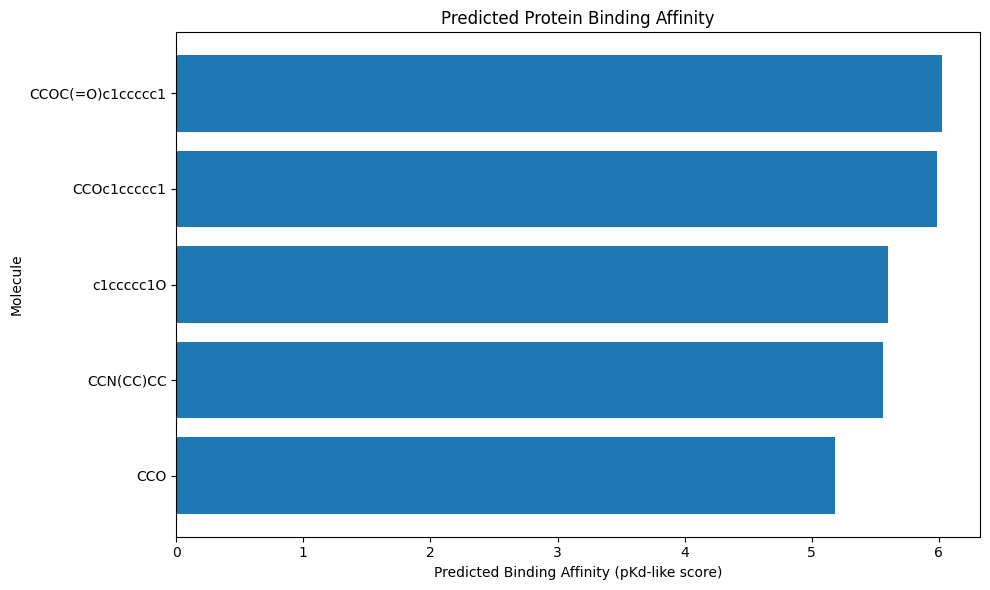

In [12]:
if 'ranked_candidates' in globals() and not ranked_candidates.empty:
    plot_df = ranked_candidates.head(15).sort_values('Predicted_Binding_Affinity_pKd')
    plt.figure(figsize=(10, 6))
    plt.barh(plot_df['SMILES'], plot_df['Predicted_Binding_Affinity_pKd'])
    plt.xlabel('Predicted Binding Affinity (pKd-like score)')
    plt.ylabel('Molecule')
    plt.title('Predicted Protein Binding Affinity')
    plt.tight_layout()
    plt.show()

### View the Streamlit Dashboard

To view the Streamlit dashboard, we need to save the Streamlit code into a Python file and then run it, exposing it via a public URL. We'll use `ngrok` for this purpose.

In [13]:
# Save the Streamlit app code to a Python file
with open('app.py', 'w') as f:
    f.write('''
import streamlit as st
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

from rdkit import Chem
from rdkit.Chem import (
    Descriptors,
    Crippen,
    Lipinski,
    rdMolDescriptors,
    Draw,
    AllChem
)

import py3Dmol
import streamlit.components.v1 as components


# ============================================================
# STREAMLIT PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="Molecular Design & Visualization",
    page_icon="🧬",
    layout="wide"
)


# ============================================================
# TITLE
# ============================================================

st.title("🧬 Molecular Design & Visualization")

st.write(
    """
    This application allows you to enter a molecule using SMILES,
    visualize its 2D and 3D structure, calculate molecular properties,
    and generate a demo protein-binding prediction.
    """
)


# ============================================================
# MOLECULAR FEATURES
# ============================================================

BINDING_FEATURES = [
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount",
    "HeavyAtomCount"
]


# ============================================================
# TRAIN DEMO BINDING MODEL
# ============================================================

@st.cache_resource
def train_demo_binding_model():

    rng = np.random.default_rng(42)

    n = 1200

    data = pd.DataFrame({

        "MolWt":
            rng.uniform(100, 650, n),

        "LogP":
            rng.uniform(-1, 7, n),

        "TPSA":
            rng.uniform(10, 180, n),

        "HBD":
            rng.integers(0, 8, n),

        "HBA":
            rng.integers(0, 12, n),

        "RotatableBonds":
            rng.integers(0, 15, n),

        "RingCount":
            rng.integers(0, 8, n),

        "HeavyAtomCount":
            rng.integers(5, 45, n)
    })


    # Synthetic/demo binding target

    noise = rng.normal(0, 0.35, n)

    data["Binding_Affinity_pKd"] = (

        5.0

        + 0.35 * data["LogP"]

        + 0.035 * data["HBA"]

        + 0.045 * data["HBD"]

        + 0.12 * data["RingCount"]

        + 0.018 * data["HeavyAtomCount"]

        - 0.0025 * data["TPSA"]

        - 0.0008 * data["MolWt"]

        - 0.025 * data["RotatableBonds"]

        + noise
    )


    X = data[BINDING_FEATURES]

    y = data["Binding_Affinity_pKd"]


    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )


    model = Pipeline([

        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ])


    model.fit(
        X_train,
        y_train
    )


    predictions = model.predict(X_test)


    mae = mean_absolute_error(
        y_test,
        predictions
    )

    r2 = r2_score(
        y_test,
        predictions
    )


    metrics = {

        "mae": mae,

        "r2": r2
    }


    return model, metrics


# Train model

binding_model, metrics = train_demo_binding_model()


# ============================================================
# MOLECULAR DESCRIPTOR FUNCTION
# ============================================================

def calculate_descriptors(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:

        return None, None


    descriptors = {

        "Molecular Weight":
            Descriptors.MolWt(mol),

        "LogP":
            Crippen.MolLogP(mol),

        "TPSA":
            rdMolDescriptors.CalcTPSA(mol),

        "H-Bond Donors":
            Lipinski.NumHDonors(mol),

        "H-Bond Acceptors":
            Lipinski.NumHAcceptors(mol),

        "Rotatable Bonds":
            Lipinski.NumRotatableBonds(mol),

        "Ring Count":
            Lipinski.RingCount(mol),

        "Heavy Atom Count":
            Lipinski.HeavyAtomCount(mol)
    }


    return mol, descriptors


# ============================================================
# PREDICT BINDING
# ============================================================

def predict_binding(smiles):

    mol, descriptors = calculate_descriptors(smiles)


    if mol is None:

        return None, None


    input_data = pd.DataFrame([
        {
            "MolWt":
                descriptors["Molecular Weight"],

            "LogP":
                descriptors["LogP"],

            "TPSA":
                descriptors["TPSA"],

            "HBD":
                descriptors["H-Bond Donors"],

            "HBA":
                descriptors["H-Bond Acceptors"],

            "RotatableBonds":
                descriptors["Rotatable Bonds"],

            "RingCount":
                descriptors["Ring Count"],

            "HeavyAtomCount":
                descriptors["Heavy Atom Count"]
        }
    ])


    prediction = binding_model.predict(
        input_data
    )[0]


    return mol, float(prediction)


# ============================================================
# 3D MOLECULAR VISUALIZATION
# ============================================================

def create_3d_visualization(mol):

    # Make a copy
    mol_3d = Chem.Mol(mol)

    # Add hydrogens
    mol_3d = Chem.AddHs(mol_3d)


    # Generate 3D coordinates

    status = AllChem.EmbedMolecule(
        mol_3d,
        randomSeed=42
    )


    if status != 0:

        return None


    # Optimize geometry

    try:

        AllChem.MMFFOptimizeMolecule(
            mol_3d
        )

    except:

        pass


    # Convert molecule to MolBlock

    mol_block = Chem.MolToMolBlock(
        mol_3d
    )


    # Create py3Dmol viewer

    viewer = py3Dmol.view(
        width=700,
        height=500
    )


    viewer.addModel(
        mol_block,
        "mol"
    )


    # Display molecule

    viewer.setStyle({

        "stick": {}

    })


    # Carbon atoms

    viewer.setStyle(

        {
            "elem": "C"
        },

        {
            "stick": {
                "radius": 0.15
            },

            "sphere": {
                "scale": 0.25
            }
        }
    )


    # Background

    viewer.setBackgroundColor(
        "white"
    )


    viewer.zoomTo()


    return viewer._make_html()


# ============================================================
# BINDING CATEGORY
# ============================================================

def get_binding_category(score):

    if score < 5:

        return "Lower"

    elif score < 7:

        return "Moderate"

    else:

        return "Higher"


# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.title("🧪 Molecule Input")


# Default molecule

default_smiles = (
    "CC(=O)OC1=CC=CC=C1C(=O)O"
)


smiles = st.sidebar.text_input(

    "Enter SMILES",

    default_smiles
)


# Example molecules

examples = {

    "Ethanol":
        "CCO",

    "Phenol":
        "c1ccccc1O",

    "Aniline":
        "c1ccccc1N",

    "Benzoic Acid":
        "c1ccccc1C(=O)O",

    "Aspirin":
        "CC(=O)OC1=CC=CC=C1C(=O)O"
}


selected_example = st.sidebar.selectbox(

    "Choose an example",

    list(examples.keys())
)


if st.sidebar.button(
    "Use Selected Molecule"
):

    st.session_state["smiles"] = (
        examples[selected_example]
    )

    st.rerun()


if "smiles" in st.session_state:

    smiles = st.session_state["smiles"]


# ============================================================
# VALIDATE SMILES
# ============================================================

mol, descriptors = calculate_descriptors(
    smiles
)


if mol is None:

    st.error(
        "❌ Invalid SMILES. Please enter a valid SMILES string."
    )

    st.stop()


# ============================================================
# MOLECULAR VISUALIZATION
# ============================================================

st.header("🔬 Molecular Visualization")


col1, col2 = st.columns(2)


# ------------------------------------------------------------
# 2D
# ------------------------------------------------------------

with col1:

    st.subheader(
        "2D Molecular Structure"
    )


    image = Draw.MolToImage(

        mol,

        size=(600, 450)
    )


    st.image(

        image,

        use_container_width=True
    )


# ------------------------------------------------------------
# 3D
# ------------------------------------------------------------

with col2:

    st.subheader(
        "Interactive 3D Structure"
    )


    html = create_3d_visualization(
        mol
    )


    if html is not None:

        components.html(

            html,

            height=520,

            scrolling=False
        )

    else:

        st.warning(
            "⚠️ Unable to generate a 3D conformer."
        )


# ============================================================
# MOLECULAR DESCRIPTORS
# ============================================================

st.header(
    "📊 Molecular Descriptors"
)


descriptor_table = pd.DataFrame(

    [
        {
            "Descriptor": name,

            "Value": round(
                float(value),
                4
            )
        }

        for name, value
        in descriptors.items()
    ]
)


st.dataframe(

    descriptor_table,

    use_container_width=True,

    hide_index=True
)


# ============================================================
# BINDING PREDICTION
# ============================================================

st.header(
    "🎯 Protein Binding Prediction"
)


_, predicted_score = predict_binding(
    smiles
)


category = get_binding_category(
    predicted_score
)


col1, col2, col3 = st.columns(3)


with col1:

    st.metric(

        "Predicted pKd-like Score",

        f"{predicted_score:.3f}"
    )


with col2:

    st.metric(

        "Binding Category",

        category
    )


with col3:

    st.metric(

        "Demo Model R²",

        f"{metrics['r2']:.3f}"
    )


# ============================================================
# IMPORTANT WARNING
# ============================================================

st.warning(
    """
    IMPORTANT:

    The binding model used here is a synthetic/demo model.
    The predicted pKd-like score is NOT experimental protein-binding
    affinity and should NOT be used as a real drug-development result.
    """
)


# ============================================================
# MULTI-MOLECULE COMPARISON
# ============================================================

st.header(
    "🧪 Compare Multiple Molecules"
)


uploaded_file = st.file_uploader(

    "Upload CSV containing a SMILES column",

    type=["csv"]
)


if uploaded_file is not None:

    input_df = pd.read_csv(
        uploaded_file
    )


    # Find SMILES column

    smiles_column = None


    for column in input_df.columns:

        if column.lower() in [
            "smiles",
            "smile"
        ]:

            smiles_column = column

            break


    if smiles_column is None:

        st.error(
            "CSV must contain a 'SMILES' column."
        )


    else:

        results = []


        for smiles_value in input_df[
            smiles_column
        ].dropna():

            smiles_value = str(
                smiles_value
            )


            molecule, desc = calculate_descriptors(
                smiles_value
            )


            if molecule is None:

                continue


            input_features = pd.DataFrame([
                {
                    "MolWt":
                        desc["Molecular Weight"],

                    "LogP":
                        desc["LogP"],

                    "TPSA":
                        desc["TPSA"],

                    "HBD":
                        desc["H-Bond Donors"],

                    "HBA":
                        desc["H-Bond Acceptors"],

                    "RotatableBonds":
                        desc["Rotatable Bonds"],

                    "RingCount":
                        desc["Ring Count"],

                    "HeavyAtomCount":
                        desc["Heavy Atom Count"]
                }
            ])


            prediction = binding_model.predict(
                input_features
            )[0]


            results.append({

                "SMILES":
                    smiles_value,

                "Predicted pKd-like":
                    round(
                        float(prediction),
                        3
                    ),

                "Binding Strength":
                    get_binding_category(
                        prediction
                    ),

                **desc
            })


        if results:

            result_df = pd.DataFrame(
                results
            )


            result_df = result_df.sort_values(

                "Predicted pKd-like",

                ascending=False
            )


            st.dataframe(

                result_df,

                use_container_width=True,

                hide_index=True
            )


        else:

            st.warning(
                "No valid molecules were found."
            )


# ============================================================
# FOOTER
# ============================================================

st.divider()

st.caption(
    """
    Molecular Design & Visualization | Educational Prototype
    """
)
''')
print("Streamlit app saved to app.py")

Streamlit app saved to app.py


In [14]:
# Install ngrok
!pip install pyngrok

In [16]:
!ngrok config add-authtoken 3CK4VmGqZ0i0MDndTaJ6uFLQ3as_5vtLUMjninSujWP7wAR8w

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
# To get an ngrok authtoken, visit: https://ngrok.com/signup
# Then, run `!ngrok config add-authtoken <YOUR_AUTHTOKEN>` in a cell.
# For example, to add an authtoken from Colab secrets, use:
# from google.colab import userdata
# authtoken = userdata.get('NGROK_AUTH_TOKEN') # Assuming you stored your token as 'NGROK_AUTH_TOKEN'
# !ngrok config add-authtoken $authtoken

# Run the Streamlit app and expose it via ngrok
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print(f"Streamlit App URL: {public_url}")

!streamlit run app.py

Streamlit App URL: NgrokTunnel: "https://entree-snaking-likely.ngrok-free.dev" -> "http://localhost:8501"


2026-09-30 23:06:20.295 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.148.77.73:8501

2026-09-30 23:06:43.159 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-09-30 23:06:43.237 Please replace `st.components.v1.html` with `st.iframe`.

`st.components.v1.html` will be removed after 2026-06-01.
2026-09-30 23:06:43.238 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-09-30 23:07:14.555 Please re

In [18]:
!pip install py3Dmol

In [17]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 60.0 MB/s eta 0:00:00


### Production upgrade: real protein target

For a scientifically meaningful protein-binding module, provide a real protein–ligand dataset containing at least **SMILES, target/protein identifier, and measured affinity** (for example Kd, Ki, IC50, or pKd/pKi with consistent units). The demonstration target above should then be replaced by those experimental labels, and the model should be trained/evaluated with target-aware splits to reduce data leakage.

For docking-based binding rather than descriptor-based prediction, the next layer can use a protein structure (PDB/mmCIF), ligand preparation, docking scores, and optional rescoring.